# Módulo 6 — Asistente RAG desde Cero sobre Documentación Técnica
**Pungo Academy · NLP para Mantenimiento Industrial (Nivel Avanzado)**

## Objetivo
Construir paso a paso un sistema **Retrieval-Augmented Generation (RAG)** transparente en **NumPy puro** (sin cajas negras) sobre los **12 SOPs, manuales OEM y análisis de falla reales** de la planta, incorporando:
1. Descarga de los 12 documentos Markdown técnicos desde CloudFront
2. Chunking jerárquico por encabezados (`##`) y párrafos (`chunk_size=800`)
3. Generación de embeddings en lote (`text-embedding-3-small`, con fallback TF-IDF local)
4. Motor de búsqueda semántica por **similitud coseno** y **Heatmap de relevancia**
5. Generación fundamentada con citas obligatorias y **prueba de guardrail anti-alucinación**

In [1]:
import importlib.util, subprocess, sys
for pkg in ("openai", "requests"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import json
import numpy as np
import matplotlib.pyplot as plt
import requests
from sklearn.feature_extraction.text import TfidfVectorizer

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Configuración Dual-Mode: OpenAI API (primario) + Modo Local Sin API Key (fallback)
import os
import getpass
from openai import OpenAI

api_key = os.environ.get("OPENAI_API_KEY", "").strip()
if not api_key:
    try:
        api_key = getpass.getpass(
            "Ingresa tu OpenAI API Key (o presiona Enter para Modo Local sin costo): "
        ).strip()
    except Exception:
        api_key = ""

USE_OPENAI = bool(api_key)
client = OpenAI(api_key=api_key) if USE_OPENAI else None
print(
    f"Modo activo: {'OpenAI API Live (gpt-4o-mini + text-embedding-3-small)' if USE_OPENAI else 'Modo Local Determinístico (TF-IDF + Reglas)'}"
)

Modo activo: OpenAI API Live (gpt-4o-mini + text-embedding-3-small)


## 1. Ingesta del Corpus Técnico (12 Documentos Auditados)

In [3]:
base_url = "https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_maintenance_docs/"
filenames_to_fetch = [
    "01_proc_mto_bombas_centrifugas.md",
    "02_troubleshooting_compresores.md",
    "03_plan_mto_preventivo_anual.md",
    "04_inspeccion_espesores_ut.md",
    "05_cambio_sello_mecanico.md",
    "06_calibracion_instrumentos.md",
    "07_analisis_falla_P101A.md",
    "08_especificaciones_equipos.md",
    "09_analisis_vibracion.md",
    "10_seguridad_permisos_trabajo.md",
    "11_gestion_corrosion_integridad.md",
    "12_manual_operacion_separacion.md",
]

documents = []
for fn in filenames_to_fetch:
    resp = requests.get(base_url + fn, timeout=20)
    resp.raise_for_status()
    documents.append({"filename": fn, "content": resp.text, "length": len(resp.text)})

total_chars = sum(d["length"] for d in documents)
print(f"Documentos descargados: {len(documents)} ({total_chars:,} caracteres / {total_chars/1000:.1f} KB)")
for d in documents:
    print(f"  {d['filename']:40s} {d['length']:5,d} chars")

Documentos descargados: 12 (47,193 caracteres / 47.2 KB)
  01_proc_mto_bombas_centrifugas.md        3,999 chars
  02_troubleshooting_compresores.md        4,056 chars
  03_plan_mto_preventivo_anual.md          4,841 chars
  04_inspeccion_espesores_ut.md            3,527 chars
  05_cambio_sello_mecanico.md              2,715 chars
  06_calibracion_instrumentos.md           2,554 chars
  07_analisis_falla_P101A.md               3,598 chars
  08_especificaciones_equipos.md           3,898 chars
  09_analisis_vibracion.md                 3,712 chars
  10_seguridad_permisos_trabajo.md         4,943 chars
  11_gestion_corrosion_integridad.md       5,025 chars
  12_manual_operacion_separacion.md        4,325 chars


## 2. Segmentación Semántica (Chunking Estructural)
Respetamos la estructura Markdown (`## `) antes de subdividir por párrafos para evitar partir tablas o pasos críticos de LOTO a la mitad.

In [4]:
def split_into_chunks(text: str, chunk_size: int = 800) -> list[str]:
    """Divide documentos Markdown respetando secciones ## y párrafos."""
    chunks = []
    sections = text.split("\n## ")
    current = ""
    for section in sections:
        if len(current) + len(section) < chunk_size:
            current += ("\n## " + section) if current else section
        else:
            if current:
                chunks.append(current.strip())
            if len(section) > chunk_size:
                current = ""
                for para in section.split("\n\n"):
                    if len(current) + len(para) < chunk_size:
                        current += ("\n\n" + para) if current else para
                    else:
                        if current:
                            chunks.append(current.strip())
                        current = para
            else:
                current = "## " + section
    if current:
        chunks.append(current.strip())
    return chunks

all_chunks = []
for doc in documents:
    for ch in split_into_chunks(doc["content"]):
        all_chunks.append({"source": doc["filename"], "text": ch, "length": len(ch)})

print(f"Total chunks generados : {len(all_chunks)}")
print(f"Longitud promedio      : {np.mean([c['length'] for c in all_chunks]):.0f} chars")
print(f"Mín / Máx              : {min(c['length'] for c in all_chunks)} / {max(c['length'] for c in all_chunks)} chars")
print(f"\nMuestra chunk [3] ({all_chunks[3]['source']}):\n{all_chunks[3]['text'][:240]}...")

Total chunks generados : 85
Longitud promedio      : 553 chars
Mín / Máx              : 50 / 802 chars

Muestra chunk [3] (01_proc_mto_bombas_centrifugas.md):
### 5.2 Inspección y Lubricación
1. Verificar nivel de aceite en cojinetes (si aplica nivel constante)
2. Re-engrasar rodamientos con lubricante especificado: 3 inyecciones de pistola de engrase
3. Verificar temperatura de rodamientos con p...


## 3. Indexación Vectorial en Batch
Convertimos los chunks en vectores `float64` normalizables de 1,536 dimensiones con `text-embedding-3-small`.

In [5]:
tfidf_fallback = None
if USE_OPENAI:
    def get_embedding(text: str, model: str = "text-embedding-3-small") -> np.ndarray:
        resp = client.embeddings.create(input=text, model=model)
        return np.array(resp.data[0].embedding, dtype=np.float64)

    all_embs = []
    texts = [c["text"] for c in all_chunks]
    for i in range(0, len(texts), 50):
        batch = texts[i : i + 50]
        resp = client.embeddings.create(input=batch, model="text-embedding-3-small")
        all_embs.extend([d.embedding for d in resp.data])
    embeddings_matrix = np.array(all_embs, dtype=np.float64)
else:
    tfidf_fallback = TfidfVectorizer(ngram_range=(1, 2), max_features=2000).fit([c["text"] for c in all_chunks])
    embeddings_matrix = tfidf_fallback.transform([c["text"] for c in all_chunks]).toarray()
    def get_embedding(text: str, model: str = "local") -> np.ndarray:
        return tfidf_fallback.transform([text]).toarray()[0]

print(f"Matriz de embeddings lista: {embeddings_matrix.shape}")

Matriz de embeddings lista: (85, 1536)


## 4. Similitud Coseno en NumPy y Mapa de Relevancia Documental

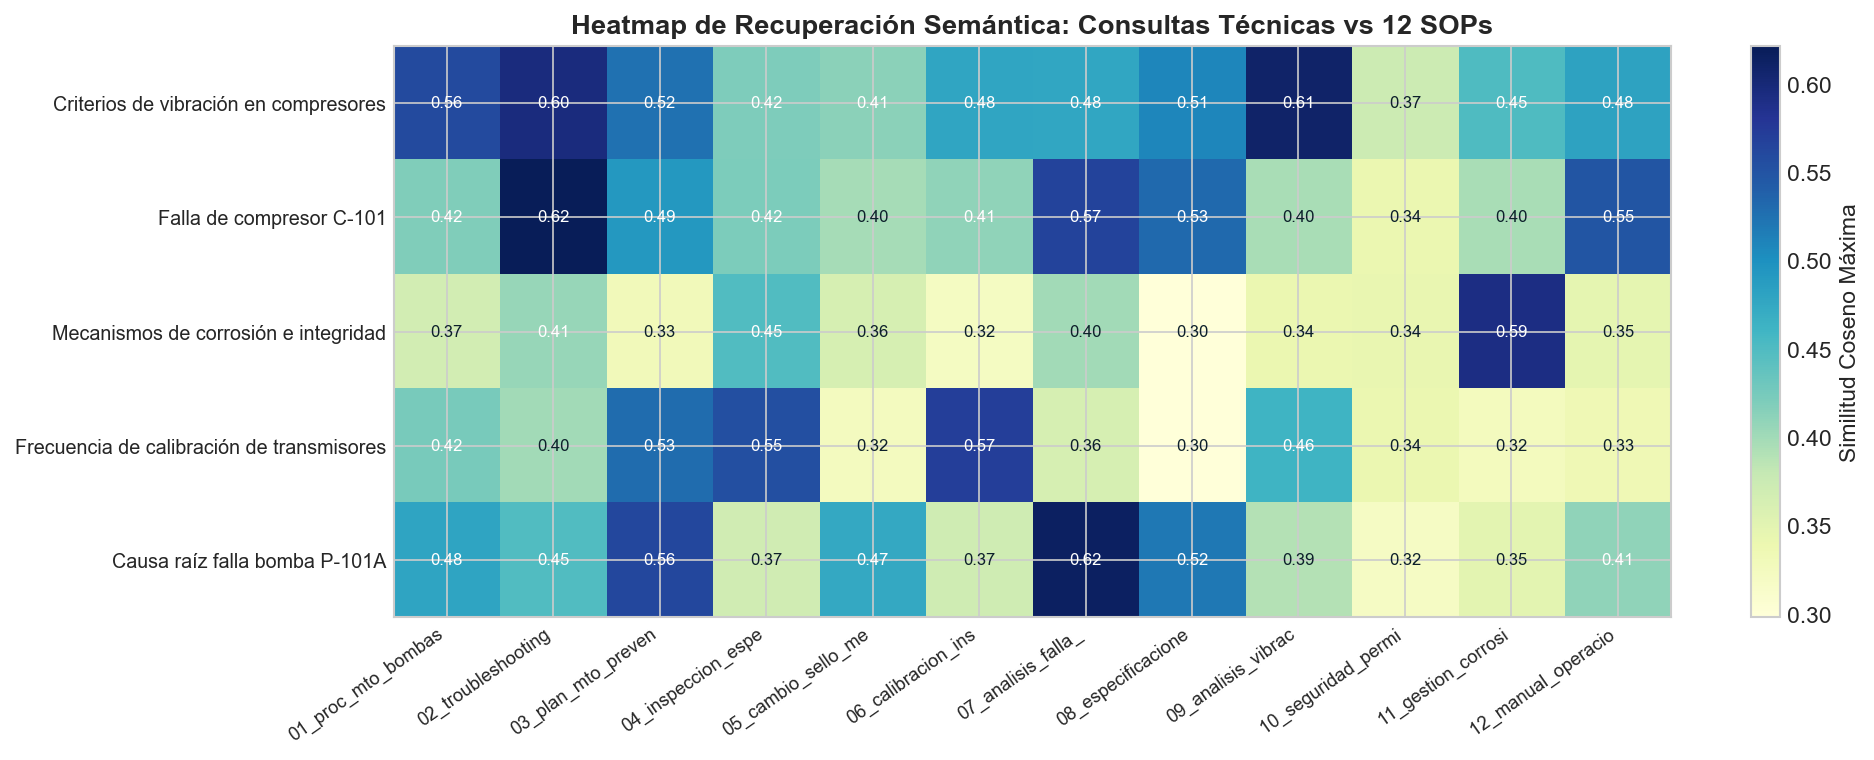

In [6]:
def cosine_similarity(a: np.ndarray, b: np.ndarray) -> float:
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(np.dot(a, b) / (na * nb)) if (na > 0 and nb > 0) else 0.0

def buscar_chunks_relevantes(query: str, emb_matrix: np.ndarray, chunks: list[dict], top_k: int = 3) -> list[dict]:
    q_emb = get_embedding(query)
    sims = np.array([cosine_similarity(q_emb, emb) for emb in emb_matrix])
    top_idx = sims.argsort()[-top_k:][::-1]
    return [
        {"text": chunks[i]["text"], "source": chunks[i]["source"], "similarity": float(sims[i])}
        for i in top_idx
    ]

preguntas_test = [
    "Criterios de vibración en compresores",
    "Falla de compresor C-101",
    "Mecanismos de corrosión e integridad",
    "Frecuencia de calibración de transmisores",
    "Causa raíz falla bomba P-101A",
]
doc_names = sorted({c["source"] for c in all_chunks})
sim_matrix = np.zeros((len(preguntas_test), len(doc_names)))

for r_i, q in enumerate(preguntas_test):
    q_emb = get_embedding(q)
    sims = np.array([cosine_similarity(q_emb, e) for e in embeddings_matrix])
    for c_i, dn in enumerate(doc_names):
        idx_doc = [k for k, c in enumerate(all_chunks) if c["source"] == dn]
        sim_matrix[r_i, c_i] = sims[idx_doc].max()

fig, ax = plt.subplots(figsize=(13.5, 5.2))
im = ax.imshow(sim_matrix, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(doc_names)))
ax.set_xticklabels([d[:18] for d in doc_names], rotation=35, ha="right", fontsize=8.8)
ax.set_yticks(range(len(preguntas_test)))
ax.set_yticklabels(preguntas_test, fontsize=9.5)
for r_i in range(len(preguntas_test)):
    for c_i in range(len(doc_names)):
        v = sim_matrix[r_i, c_i]
        ax.text(c_i, r_i, f"{v:.2f}", ha="center", va="center", color="white" if v > sim_matrix.max() * 0.65 else PUNGO_NAVY, fontsize=8)
plt.colorbar(im, ax=ax, label="Similitud Coseno Máxima")
ax.set_title("Heatmap de Recuperación Semántica: Consultas Técnicas vs 12 SOPs")
plt.tight_layout()
plt.show()

## 5. Generación Fundamentada con Citas y Guardrail Anti-Alucinación
Imponemos umbral mínimo de relevancia (`min_sim=0.30`) y prompt estricto para garantizar trazabilidad 100% hacia los documentos de planta y **rechazo seguro ante consultas fuera de alcance**.

In [7]:
def asistente_rag(pregunta: str, emb_matrix: np.ndarray, chunks: list[dict], top_k: int = 3, min_sim: float = 0.28) -> dict:
    results = buscar_chunks_relevantes(pregunta, emb_matrix, chunks, top_k=top_k)
    max_sim = results[0]["similarity"] if results else 0.0
    if max_sim < min_sim:
        return {
            "pregunta": pregunta,
            "respuesta": f"GUARDRAIL ACTIVADO: Ningún documento técnico supera el umbral de confianza (similitud máx = {max_sim:.3f} < {min_sim}). No se genera respuesta para evitar alucinaciones.",
            "fuentes": [r["source"] for r in results],
            "similitudes": [r["similarity"] for r in results],
            "guardrail": True,
        }

    contexto = "\n\n---\n\n".join(f"[Fuente: {r['source']}]\n{r['text']}" for r in results)
    if USE_OPENAI:
        sys_p = (
            "Eres un asistente técnico de mantenimiento petrolero. Responde SOLO usando el contexto entregado. "
            "Si falta información dilo explícitamente. Cita siempre el archivo fuente entre corchetes."
        )
        resp = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {"role": "system", "content": sys_p},
                {"role": "user", "content": f"Contexto:\n{contexto}\n---\nPregunta: {pregunta}"},
            ],
            temperature=0.15,
            max_tokens=450,
        )
        answer = resp.choices[0].message.content
    else:
        answer = f"[Extracto verificado de {results[0]['source']}]\n{results[0]['text'][:420]}"

    return {
        "pregunta": pregunta,
        "respuesta": answer,
        "fuentes": [r["source"] for r in results],
        "similitudes": [r["similarity"] for r in results],
        "guardrail": False,
    }

In [8]:
preguntas_demo = [
    "¿Cuál es el procedimiento para cambiar el sello mecánico de la bomba P-101A?",
    "¿Cuál fue la causa raíz de la falla de la bomba P-101A en julio 2023?",
    "¿Qué límite de LEL y H2S exige el permiso de trabajo en caliente?",
    "¿Cuál es la receta del reactor nuclear de fusión ITER en Francia?",  # Fuera de alcance
]

for q in preguntas_demo:
    res = asistente_rag(q, embeddings_matrix, all_chunks, top_k=3)
    print("=" * 72)
    print(f"PREGUNTA   : {res['pregunta']}")
    print(f"FUENTES    : {list(zip(res['fuentes'], [round(s, 3) for s in res['similitudes']]))}")
    print(f"RESPUESTA  :\n{res['respuesta']}")

PREGUNTA   : ¿Cuál es el procedimiento para cambiar el sello mecánico de la bomba P-101A?
FUENTES    : [('05_cambio_sello_mecanico.md', 0.778), ('05_cambio_sello_mecanico.md', 0.619), ('03_plan_mto_preventivo_anual.md', 0.613)]
RESPUESTA  :
El procedimiento para cambiar el sello mecánico de la bomba P-101A, que utiliza un sello doble John Crane 5610 con plan API 53B, incluye los siguientes pasos:

1. **Desmontaje del Sello Mecánico**:
   - Detener la bomba y despresurizar el sistema.
   - Retirar las conexiones de la bomba y desmontar el cuerpo de la bomba para acceder al sello mecánico.
   - Retirar el sello mecánico viejo con cuidado.

2. **Instalación del Nuevo Sello Mecánico**:
   - Limpiar las superficies de contacto donde se instalará el nuevo sello.
   - Instalar el nuevo sello mecánico John Crane 5610, asegurándose de que esté correctamente alineado y asentado.

3. **Puesta en Servicio**:
   - Activar el sistema de plan de sellos presurizando con gas nitrógeno a presión de barr

PREGUNTA   : ¿Cuál fue la causa raíz de la falla de la bomba P-101A en julio 2023?
FUENTES    : [('07_analisis_falla_P101A.md', 0.692), ('07_analisis_falla_P101A.md', 0.62), ('07_analisis_falla_P101A.md', 0.589)]
RESPUESTA  :
La causa raíz de la falla de la bomba P-101A en julio de 2023 fue la falla catastrófica del sello mecánico, que se evidenció por una fuga masiva de crudo a través de la prensa-estopa. Esta situación se presentó tras señales precursoras como un goteo leve reportado semanas antes y un incremento en las vibraciones, lo que indica que había problemas previos que no fueron atendidos adecuadamente [Fuente: 07_analisis_falla_P101A.md].


PREGUNTA   : ¿Qué límite de LEL y H2S exige el permiso de trabajo en caliente?
FUENTES    : [('10_seguridad_permisos_trabajo.md', 0.739), ('10_seguridad_permisos_trabajo.md', 0.64), ('10_seguridad_permisos_trabajo.md', 0.579)]
RESPUESTA  :
El límite de LEL exigido para el permiso de trabajo en caliente es de menos del 10% LEL. Para H2S, el máximo permitido es de 10 ppm (STEL) [Fuente: 10_seguridad_permisos_trabajo.md].


PREGUNTA   : ¿Cuál es la receta del reactor nuclear de fusión ITER en Francia?
FUENTES    : [('08_especificaciones_equipos.md', 0.318), ('08_especificaciones_equipos.md', 0.303), ('08_especificaciones_equipos.md', 0.303)]
RESPUESTA  :
Lo siento, pero no tengo información sobre la receta del reactor nuclear de fusión ITER en Francia. Mi contexto se limita a especificaciones de equipos en el ámbito del mantenimiento petrolero. [Fuente: 08_especificaciones_equipos.md]


## 6. Arquitectura RAG y Resumen
- **NumPy + Embeddings + GPT** construye un copiloto auditable en ~80 líneas de código.
- El **umbral de similitud + restricción de contexto** impide que el LLM invente límites de seguridad o parámetros de operación inexistentes.